# Probabilistic SMS Spam Detection
**BAMAT207 Probability and Statistics - Project Activity**

Topic: Probability and Random Variables. Dataset: SMS Spam Collection (UCI).

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

## 1. Dataset Handling
Loads the local file `data/SMSSpamCollection` (or downloads it from UCI with `ucimlrepo`, e.g. on Google Colab).

In [2]:
LOCAL = Path("data/SMSSpamCollection")
if LOCAL.exists():
    df = pd.read_csv(LOCAL, sep="\t", header=None, names=["label", "message"], quoting=3, encoding="utf-8")
else:
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        %pip install -q ucimlrepo
        from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=228)
    df = pd.concat([d.data.targets, d.data.features], axis=1)
    df.columns = ["label", "message"]

print("Raw shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

Raw shape: (5574, 2)
Missing values:
 label      0
message    0
dtype: int64


In [3]:
df = df.dropna().copy()
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].str.strip()

n_dups = df.duplicated(subset="message").sum()
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print("Duplicate messages removed:", n_dups)

df["y"] = df["label"].map({"ham": 0, "spam": 1})   # Spam = 1, Ham = 0
print("Cleaned shape:", df.shape)
df.head()

Duplicate messages removed: 414
Cleaned shape: (5160, 3)


,label,message,y
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 2. Dataset Analysis
$P(\text{Spam}) = \dfrac{\text{spam messages}}{\text{total messages}}$

Total = 5160, Spam = 642, Ham = 4518
P(Spam) = 642/5160 = 0.1244
P(Ham)  = 4518/5160 = 0.8756


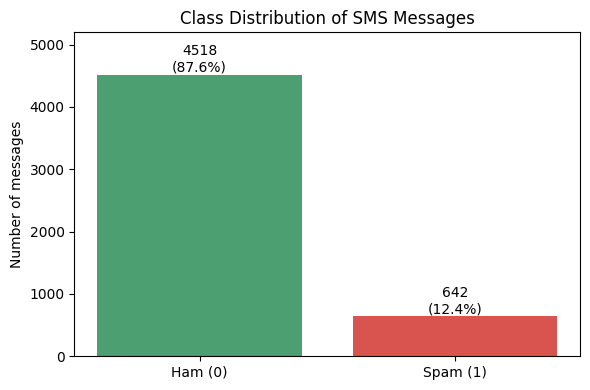

In [4]:
n = len(df)
n_spam = int((df.y == 1).sum()); n_ham = int((df.y == 0).sum())
p_spam, p_ham = n_spam / n, n_ham / n
print(f"Total = {n}, Spam = {n_spam}, Ham = {n_ham}")
print(f"P(Spam) = {n_spam}/{n} = {p_spam:.4f}")
print(f"P(Ham)  = {n_ham}/{n} = {p_ham:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Ham (0)", "Spam (1)"], [n_ham, n_spam], color=["#4C9F70", "#D9534F"])
for b, c, p in zip(bars, [n_ham, n_spam], [p_ham, p_spam]):
    ax.text(b.get_x() + b.get_width()/2, c, f"{c}\n({p:.1%})", ha="center", va="bottom")
ax.set_ylabel("Number of messages"); ax.set_title("Class Distribution of SMS Messages")
ax.set_ylim(0, max(n_ham, n_spam) * 1.15)
plt.tight_layout(); plt.show()

## 3. Word-Based Probability Analysis
$P(\text{Spam}|\text{word}) = \dfrac{\text{spam messages containing word}}{\text{messages containing word}}$, verified with Bayes' theorem:

$P(\text{Spam}|\text{word}) = \dfrac{P(\text{word}|\text{Spam})\,P(\text{Spam})}{P(\text{word})}$

In [5]:
words = ["free", "prize", "win", "urgent", "offer"]
is_spam = df.y == 1
rows = []
for w in words:
    pat = re.compile(rf"\b{re.escape(w)}\b", re.IGNORECASE)
    has = df.message.apply(lambda t: bool(pat.search(t)))
    n_w, n_ws = int(has.sum()), int((has & is_spam).sum())
    direct = n_ws / n_w
    p_w, p_w_s = n_w / n, n_ws / n_spam
    bayes = p_w_s * p_spam / p_w
    rows.append({"word": w, "msgs_with_word": n_w, "spam_with_word": n_ws, "P(Word)": p_w,
                 "P(Word|Spam)": p_w_s, "P(Spam|Word) direct": direct,
                 "P(Spam|Word) Bayes": bayes, "match": bool(np.isclose(direct, bayes))})
word_table = pd.DataFrame(rows).round(4)
word_table

,word,msgs_with_word,spam_with_word,P(Word),P(Word|Spam),P(Spam|Word) direct,P(Spam|Word) Bayes,match
0,free,199,144,0.0386,0.2243,0.7236,0.7236,True
1,prize,70,70,0.0136,0.1090,1.0000,1.0000,True
2,win,53,47,0.0103,0.0732,0.8868,0.8868,True
3,urgent,61,56,0.0118,0.0872,0.9180,0.9180,True
4,offer,30,24,0.0058,0.0374,0.8000,0.8000,True


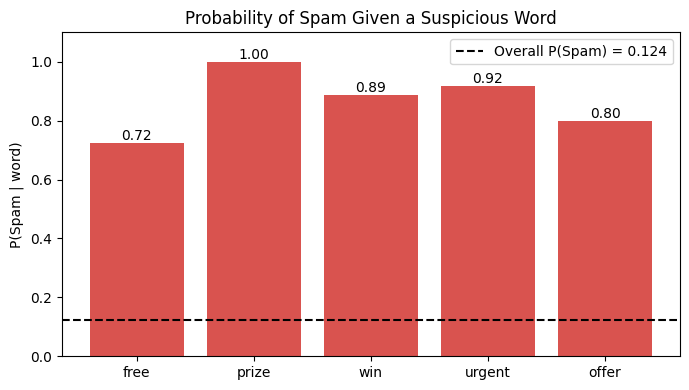

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(word_table.word, word_table["P(Spam|Word) direct"], color="#D9534F")
ax.axhline(p_spam, color="black", ls="--", label=f"Overall P(Spam) = {p_spam:.3f}")
for i, v in enumerate(word_table["P(Spam|Word) direct"]):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center")
ax.set_ylim(0, 1.1); ax.set_ylabel("P(Spam | word)")
ax.set_title("Probability of Spam Given a Suspicious Word"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Random Variable Analysis
$Y=1$ if spam, $Y=0$ if ham, so $Y$ is Bernoulli($p$) with $p=P(\text{Spam})$: $E(Y)=p$, $\operatorname{Var}(Y)=p(1-p)$.

In [7]:
p = p_spam
print(f"E(Y)   = p        = {p:.4f}")
print(f"Var(Y) = p(1 - p) = {p*(1-p):.4f}")
print(f"Check with numpy: mean = {np.mean(df.y):.4f}, var = {np.var(df.y):.4f}")

E(Y)   = p        = 0.1244
Var(Y) = p(1 - p) = 0.1089
Check with numpy: mean = 0.1244, var = 0.1089


## 5. Data Preparation
80% training / 20% testing, stratified to keep the spam-ham proportion; text converted to word counts with `CountVectorizer`.

In [8]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df.message, df.y, test_size=0.20, stratify=df.y, random_state=42)
print(f"Train: {len(X_train_text)} (spam share {y_train.mean():.4f}) | Test: {len(X_test_text)} (spam share {y_test.mean():.4f})")

vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Train: 4128 (spam share 0.1245) | Test: 1032 (spam share 0.1240)
Vocabulary size: 7673


## 6. Model Building - Multinomial Naive Bayes

In [9]:
model = MultinomialNB()
model.fit(X_train, y_train)
print("Model trained.")

Model trained.


## 7. Model Evaluation

In [10]:
y_pred = model.predict(X_test)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"], digits=4))

Accuracy : 0.9826
Precision: 0.9508
Recall   : 0.9062


F1-score : 0.9280

              precision    recall  f1-score   support

         Ham     0.9868    0.9934    0.9901       904
        Spam     0.9508    0.9062    0.9280       128

    accuracy                         0.9826      1032
   macro avg     0.9688    0.9498    0.9590      1032
weighted avg     0.9823    0.9826    0.9824      1032



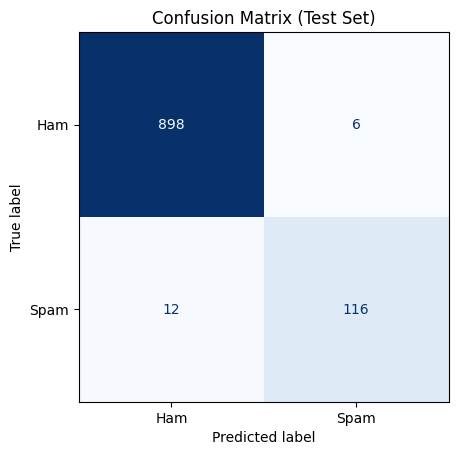

Spam incorrectly classified as genuine (False Negatives): 12
Genuine incorrectly classified as spam (False Positives): 6


In [11]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
ConfusionMatrixDisplay(cm, display_labels=["Ham", "Spam"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (Test Set)"); plt.show()
print(f"Spam incorrectly classified as genuine (False Negatives): {fn}")
print(f"Genuine incorrectly classified as spam (False Positives): {fp}")

In [12]:
res = pd.DataFrame({"message": X_test_text.values, "actual": y_test.values, "predicted": y_pred})
print("Spam classified as genuine:")
display(res[(res.actual == 1) & (res.predicted == 0)][["message"]])
print("Genuine classified as spam:")
display(res[(res.actual == 0) & (res.predicted == 1)][["message"]])

Spam classified as genuine:


,message
201,"SMS. ac JSco: Energy is high, but u may not kn..."
205,Sorry I missed your call let's talk when you h...
299,LookAtMe!: Thanks for your purchase of a video...
354,Hi I'm sue. I am 20 years old and work as a la...
389,Babe: U want me dont u baby! Im nasty and have...
562,Block Breaker now comes in deluxe format with ...
636,thesmszone.com lets you send free anonymous an...
846,CLAIRE here am havin borin time & am now alone...
848,dating:i have had two of these. Only started a...
863,Guess who am I?This is the first time I create...


Genuine classified as spam:


,message
105,I (Career Tel) have added u as a contact on IN...
254,Nokia phone is lovly..
508,Have you laid your airtel line to rest?
706,Unlimited texts. Limited minutes.
736,"Mostly sports type..lyk footbl,crckt.."
818,"Received, understood n acted upon!"


## 8. Real-Time Testing
Change the message below and re-run the cell, or run the second cell to type messages interactively.

In [13]:
def predict_message(text):
    proba = model.predict_proba(vectorizer.transform([text]))[0]
    p_ham, p_spam = proba
    print(f"Message           : {text}")
    print(f"Prediction        : {'Spam' if p_spam >= 0.5 else 'Ham (Genuine)'}")
    print(f"P(Spam | Message) = {p_spam:.2f}")
    print(f"P(Ham  | Message) = {p_ham:.2f}\n")

predict_message("Congratulations! You have won a free prize. Claim now.")
predict_message("Hey, are we still meeting for lunch at 1pm tomorrow?")
predict_message("URGENT! Your mobile number has won a 2000 cash prize. Call 09061701461 now")

Message           : Congratulations! You have won a free prize. Claim now.
Prediction        : Spam
P(Spam | Message) = 1.00
P(Ham  | Message) = 0.00

Message           : Hey, are we still meeting for lunch at 1pm tomorrow?
Prediction        : Ham (Genuine)
P(Spam | Message) = 0.00
P(Ham  | Message) = 1.00

Message           : URGENT! Your mobile number has won a 2000 cash prize. Call 09061701461 now
Prediction        : Spam
P(Spam | Message) = 1.00
P(Ham  | Message) = 0.00



In [ ]:
# Interactive prompt (type 'quit' to stop)
while True:
    text = input("SMS> ").strip()
    if text.lower() in {"quit", "exit", "q"}:
        break
    if text:
        predict_message(text)